# Лабораторна робота № 4
## Бінарна класифікація табличних даних на прикладі Titanic

**Дисципліна:** Інтелектуальний аналіз даних

**Тема:** Побудова та оцінювання моделі бінарної класифікації з коректним поділом даних, підготовкою різнотипних ознак у Pipeline та аналізом помилок.

**Мета:** Навчитися виконувати повний цикл бінарної класифікації.

**Варіант:** 17

In [14]:
import sys

!"{sys.executable}" -m pip install seaborn

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

np.random.seed(SEED)

print("Бібліотеки успішно імпортовано")
print("SEED =", SEED)

Бібліотеки успішно імпортовано
SEED = 42


In [16]:
import pandas as pd

df = pd.read_csv("titanic.csv")

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [17]:
print("Перші 5 рядків:")
display(df.head())

Перші 5 рядків:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [18]:
print("Інформація про таблицю:")
df.info()

Інформація про таблицю:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 116.9 KB


In [19]:
print("Описова статистика:")
display(df.describe(include="all"))

Описова статистика:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 107


In [21]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": df.isna().mean() * 100
}).sort_values("percent", ascending=False)

display(missing.round(2))

,count,percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


In [22]:
class_balance = pd.DataFrame({
    "count": df["survived"].value_counts().sort_index(),
    "percent": df["survived"].value_counts(normalize=True).sort_index() * 100
})

display(class_balance.round(2))

,count,percent
survived,,
0,549,61.62
1,342,38.38


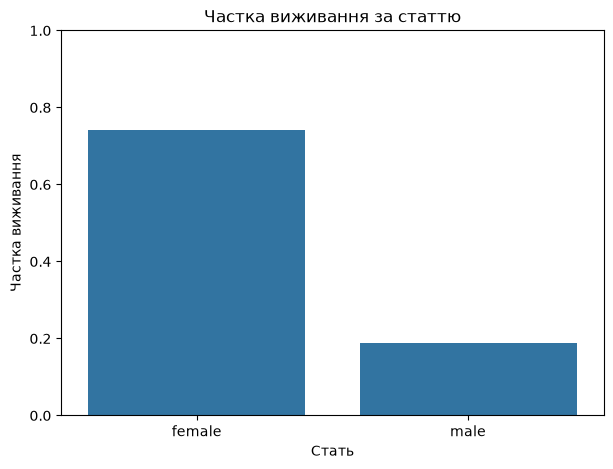

In [23]:
survival_by_sex = (
    df.groupby("sex")["survived"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=survival_by_sex,
    x="sex",
    y="survived"
)

plt.title("Частка виживання за статтю")
plt.xlabel("Стать")
plt.ylabel("Частка виживання")
plt.ylim(0, 1)

plt.show()

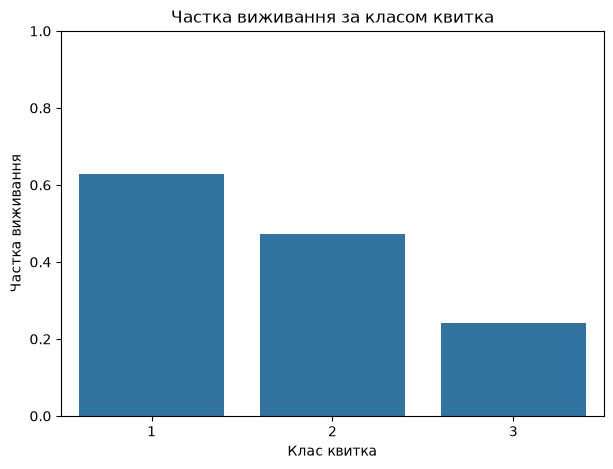

In [24]:
survival_by_class = (
    df.groupby("pclass")["survived"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=survival_by_class,
    x="pclass",
    y="survived"
)

plt.title("Частка виживання за класом квитка")
plt.xlabel("Клас квитка")
plt.ylabel("Частка виживання")
plt.ylim(0, 1)

plt.show()

### Висновок

У наборі Titanic присутні пропущені значення, зокрема в ознаці `age`, тому рядки з пропусками не видаляємо. Пропуски будуть оброблені пізніше всередині Pipeline.

Також було перевірено баланс цільового класу `survived`.

За графіками можна побачити відмінності частки виживання залежно від статі та класу квитка. Ці ознаки можуть бути корисними для побудови моделі класифікації.

In [25]:
data = df.copy()

# Створення розміру сім'ї
data["family_size"] = data["sibsp"] + data["parch"] + 1

# Числові ознаки
numeric_features = [
    "age",
    "sibsp",
    "parch",
    "fare",
    "family_size"
]

# Категоріальні ознаки
categorical_features = [
    "pclass",
    "sex",
    "embarked"
]

# Матриця ознак
X = data[numeric_features + categorical_features]

# Цільова змінна
y = data["survived"]

print("Числові ознаки:")
print(numeric_features)

print("\nКатегоріальні ознаки:")
print(categorical_features)

print("\nРозмір X:", X.shape)
print("Розмір y:", y.shape)

Числові ознаки:
['age', 'sibsp', 'parch', 'fare', 'family_size']

Категоріальні ознаки:
['pclass', 'sex', 'embarked']

Розмір X: (891, 8)
Розмір y: (891,)


In [26]:
display(X.head())

,age,sibsp,parch,fare,family_size,pclass,sex,embarked
0,22.0,1,0,7.2500,2,3,male,S
1,38.0,1,0,71.2833,2,1,female,C
2,26.0,0,0,7.9250,1,3,female,S
3,35.0,1,0,53.1000,2,1,female,S
4,35.0,0,0,8.0500,1,3,male,S


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nЧастка позитивного класу:")

print("У всьому наборі:", round(y.mean(), 4))
print("У train:", round(y_train.mean(), 4))
print("У test:", round(y_test.mean(), 4))

X_train: (712, 8)
X_test: (179, 8)

Частка позитивного класу:
У всьому наборі: 0.3838
У train: 0.3834
У test: 0.3855


### Висновок

Дані поділено у співвідношенні 80/20. Параметр `stratify=y` дозволяє зберегти приблизно однакове співвідношення класів у навчальній та тестовій вибірках.

Параметр `random_state=42` забезпечує відтворюваність результату.

Тестова вибірка не використовується для навчання моделі, вибору ознак або підбору порога.

In [28]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Перші прогнози DummyClassifier:")
print(baseline_pred[:20])

Перші прогнози DummyClassifier:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### Висновок

`DummyClassifier` є базовою моделлю, яка завжди прогнозує найчастіший клас. Вона потрібна для створення baseline, з яким порівнюватиметься Logistic Regression.

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [30]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [31]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [32]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [33]:
model = Pipeline([
    ("prepare", preprocessor),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=SEED
        )
    )
])

print(model)

Pipeline(steps=[('prepare',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'sibsp', 'parch',
                                                   'fare', 'family_size']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown=

### Висновок

Підготовку числових і категоріальних ознак об'єднано за допомогою `ColumnTransformer`, а підготовку даних і Logistic Regression об'єднано в один `Pipeline`.

Такий підхід запобігає витоку даних, оскільки параметри `imputer`, `scaler` та `encoder` навчаються тільки на навчальній вибірці.

In [34]:
model.fit(X_train, y_train)

print("Модель успішно навчена.")

Модель успішно навчена.


In [35]:
# Прогнозовані класи
y_pred = model.predict(X_test)

# Прогнозовані ймовірності класу 1
y_proba = model.predict_proba(X_test)[:, 1]

print("Перші 10 прогнозованих класів:")
print(y_pred[:10])

print("\nПерші 10 прогнозованих ймовірностей:")
print(np.round(y_proba[:10], 3))

Перші 10 прогнозованих класів:
[0 0 0 0 1 0 1 0 0 0]

Перші 10 прогнозованих ймовірностей:
[0.068 0.048 0.157 0.036 0.671 0.441 0.767 0.307 0.345 0.175]


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [37]:
def classification_metrics(y_true, y_hat):
    return {
        "accuracy": accuracy_score(
            y_true,
            y_hat
        ),
        "precision": precision_score(
            y_true,
            y_hat,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_hat,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_hat,
            zero_division=0
        )
    }

In [38]:
results = pd.DataFrame([
    classification_metrics(
        y_test,
        baseline_pred
    ),
    classification_metrics(
        y_test,
        y_pred
    )
],
index=[
    "DummyClassifier",
    "LogisticRegression"
])

results.loc[
    "LogisticRegression",
    "roc_auc"
] = roc_auc_score(
    y_test,
    y_proba
)

results.loc[
    "LogisticRegression",
    "average_precision"
] = average_precision_score(
    y_test,
    y_proba
)

display(results.round(3))

,accuracy,precision,recall,f1,roc_auc,average_precision
DummyClassifier,0.615,0.000,0.000,0.000,NaN,NaN
LogisticRegression,0.804,0.793,0.667,0.724,0.843,0.786


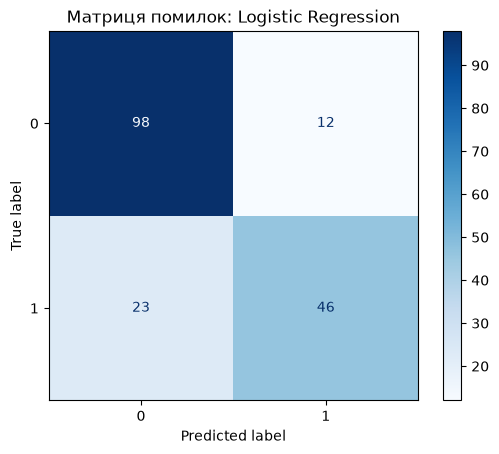

In [39]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Матриця помилок: Logistic Regression")
plt.show()

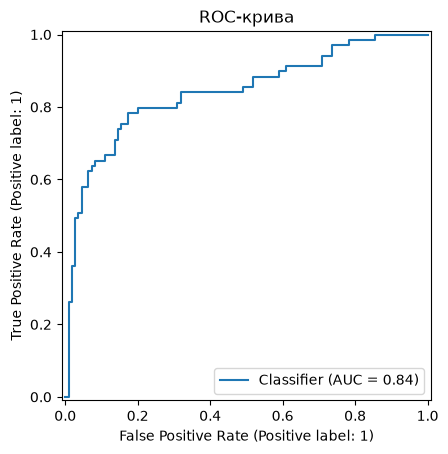

In [40]:
RocCurveDisplay.from_predictions(
    y_test,
    y_proba
)

plt.title("ROC-крива")
plt.show()

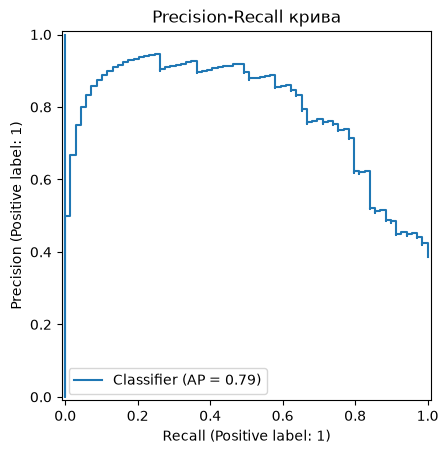

In [41]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_proba
)

plt.title("Precision-Recall крива")
plt.show()

### Висновок

Logistic Regression оцінено за accuracy, precision, recall та F1. Додатково використано ROC AUC і Average Precision.

ROC AUC та Average Precision розраховуються за прогнозованими ймовірностями, а не за готовими класами, оскільки вони оцінюють поведінку моделі за різними порогами.

Confusion Matrix дозволяє окремо побачити TP, TN, FP та FN.

In [42]:
threshold_rows = []

for threshold in [0.30, 0.50, 0.70]:

    pred_t = (
        y_proba >= threshold
    ).astype(int)

    row = classification_metrics(
        y_test,
        pred_t
    )

    row["threshold"] = threshold

    threshold_rows.append(row)

threshold_results = (
    pd.DataFrame(threshold_rows)
    .set_index("threshold")
)

display(
    threshold_results.round(3)
)

,accuracy,precision,recall,f1
threshold,,,,
0.3,0.771,0.671,0.797,0.728
0.5,0.804,0.793,0.667,0.724
0.7,0.788,0.897,0.507,0.648


### Висновок

Зменшення порога рішення зазвичай призводить до збільшення recall, оскільки модель частіше відносить об'єкти до позитивного класу.

Водночас precision може зменшуватися, оскільки збільшується кількість хибнопозитивних прогнозів.

Для умовного сценарію Titanic, де пропустити пасажира, який фактично вижив, вважається дорожчою помилкою, доцільно розглядати нижчий поріг.

Вибір порога є навчальним аналізом і не означає, що цей поріг є оптимальним для реального застосування.

In [43]:
error_analysis = X_test.copy()

error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred
error_analysis["probability"] = y_proba

In [44]:
false_positive = error_analysis.query(
    "actual == 0 and predicted == 1"
)

display(
    false_positive
    .sort_values(
        "probability",
        ascending=False
    )
    .head(5)
)

,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
297,2.0,1,2,151.5500,4,1,female,S,0,1,0.965727
199,24.0,0,0,13.0000,1,2,female,S,0,1,0.838099
501,21.0,0,0,7.7500,1,3,female,Q,0,1,0.772259
502,NaN,0,0,7.6292,1,3,female,Q,0,1,0.718875
593,NaN,0,2,7.7500,3,3,female,Q,0,1,0.683636


In [45]:
false_negative = error_analysis.query(
    "actual == 1 and predicted == 0"
)

display(
    false_negative
    .sort_values(
        "probability",
        ascending=True
    )
    .head(5)
)

,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
570,62.0,0,0,10.5000,1,2,male,S,1,0,0.083417
444,NaN,0,0,8.1125,1,3,male,S,1,0,0.087915
804,27.0,0,0,6.9750,1,3,male,S,1,0,0.092276
146,27.0,0,0,7.7958,1,3,male,S,1,0,0.092468
271,25.0,0,0,0.0000,1,3,male,S,1,0,0.097051


In [46]:
print("Кількість False Positive:", len(false_positive))
print("Кількість False Negative:", len(false_negative))

Кількість False Positive: 12
Кількість False Negative: 23


In [47]:
print("5 найбільш упевнених False Positive:")
display(
    false_positive
    .sort_values(
        "probability",
        ascending=False
    )
    .head(5)
)

5 найбільш упевнених False Positive:


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
297,2.0,1,2,151.5500,4,1,female,S,0,1,0.965727
199,24.0,0,0,13.0000,1,2,female,S,0,1,0.838099
501,21.0,0,0,7.7500,1,3,female,Q,0,1,0.772259
502,NaN,0,0,7.6292,1,3,female,Q,0,1,0.718875
593,NaN,0,2,7.7500,3,3,female,Q,0,1,0.683636


In [48]:
print("5 найбільш упевнених False Negative:")
display(
    false_negative
    .sort_values(
        "probability",
        ascending=True
    )
    .head(5)
)

5 найбільш упевнених False Negative:


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
570,62.0,0,0,10.5000,1,2,male,S,1,0,0.083417
444,NaN,0,0,8.1125,1,3,male,S,1,0,0.087915
804,27.0,0,0,6.9750,1,3,male,S,1,0,0.092276
146,27.0,0,0,7.7958,1,3,male,S,1,0,0.092468
271,25.0,0,0,0.0000,1,3,male,S,1,0,0.097051


### Аналіз помилок

**False Positive (FP)** — модель передбачила, що пасажир вижив, але фактично він не вижив.

**False Negative (FN)** — модель передбачила, що пасажир не вижив, але фактично він вижив.

Можливими причинами помилок є недостатня кількість ознак для повного опису пасажира та перекриття характеристик між класами.

Для покращення експерименту можна перевірити додаткові ознаки та порівняти Logistic Regression з іншими моделями, використовуючи однакову процедуру оцінювання.

In [49]:
from sklearn.calibration import calibration_curve

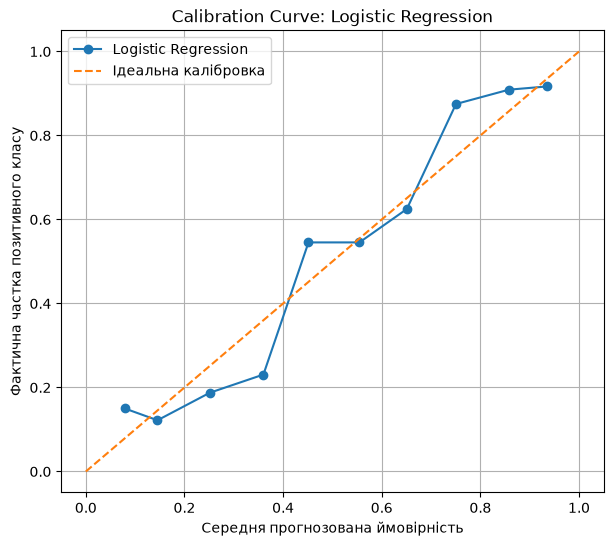

In [50]:
prob_true, prob_pred = calibration_curve(
    y_test,
    y_proba,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ідеальна калібровка"
)

plt.xlabel(
    "Середня прогнозована ймовірність"
)

plt.ylabel(
    "Фактична частка позитивного класу"
)

plt.title(
    "Calibration Curve: Logistic Regression"
)

plt.legend()
plt.grid(True)

plt.show()

### Висновок за індивідуальним завданням

Calibration Curve використовується для оцінювання якості прогнозованих імовірностей.

Ідеально калібрована модель повинна розташовуватися поблизу діагоналі `y = x`.

Наприклад, якщо модель прогнозує середню ймовірність виживання 0.7 для певної групи пасажирів, приблизно 70% таких пасажирів мають фактично належати до позитивного класу.

Чим ближче точки calibration curve до діагоналі, тим краще прогнозовані ймовірності відповідають фактичним часткам позитивного класу.

При цьому калібровка є окремою характеристикою моделі та не тотожна її здатності правильно розділяти класи.

In [51]:
cm = confusion_matrix(
    y_test,
    y_pred
)

tn, fp, fn, tp = cm.ravel()

print("TN =", tn)
print("FP =", fp)
print("FN =", fn)
print("TP =", tp)

TN = 98
FP = 12
FN = 23
TP = 46


In [52]:
lr = results.loc["LogisticRegression"]
dummy = results.loc["DummyClassifier"]

print("=" * 60)
print("ЗАГАЛЬНИЙ ВИСНОВОК")
print("=" * 60)

if lr["accuracy"] > dummy["accuracy"]:
    print(
        "Logistic Regression перевищила DummyClassifier "
        "за accuracy."
    )
else:
    print(
        "Logistic Regression не перевищила DummyClassifier "
        "за accuracy."
    )

print(f"\nAccuracy: {lr['accuracy']:.3f}")
print(f"Precision: {lr['precision']:.3f}")
print(f"Recall: {lr['recall']:.3f}")
print(f"F1: {lr['f1']:.3f}")
print(f"ROC AUC: {lr['roc_auc']:.3f}")
print(
    f"Average Precision: "
    f"{lr['average_precision']:.3f}"
)

print("\nМатриця помилок:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

if fn > fp:
    print(
        "\nУ тестовій вибірці кількість FN "
        "більша за кількість FP."
    )
elif fp > fn:
    print(
        "\nУ тестовій вибірці кількість FP "
        "більша за кількість FN."
    )
else:
    print(
        "\nКількість FP та FN однакова."
    )

print(
    "\nЗміна порога створює компроміс "
    "між precision та recall."
)

print(
    "Експеримент має обмеження: набір містить "
    "обмежену кількість ознак, пропуски та результати "
    "залежать від конкретного train/test поділу."
)

ЗАГАЛЬНИЙ ВИСНОВОК
Logistic Regression перевищила DummyClassifier за accuracy.

Accuracy: 0.804
Precision: 0.793
Recall: 0.667
F1: 0.724
ROC AUC: 0.843
Average Precision: 0.786

Матриця помилок:
TN = 98
FP = 12
FN = 23
TP = 46

У тестовій вибірці кількість FN більша за кількість FP.

Зміна порога створює компроміс між precision та recall.
Експеримент має обмеження: набір містить обмежену кількість ознак, пропуски та результати залежать від конкретного train/test поділу.


# Запитання для самоперевірки

### 1. Чим прогнозована ймовірність відрізняється від прогнозованого класу?

Прогнозована ймовірність показує, наскільки модель оцінює ймовірність належності об'єкта до позитивного класу. Прогнозований клас отримується після порівняння цієї ймовірності з певним порогом, наприклад 0.5.

### 2. Навіщо застосовувати `stratify=y` під час поділу?

`stratify=y` дозволяє зберегти приблизно однакове співвідношення класів у навчальній і тестовій вибірках.

### 3. Чому SimpleImputer потрібно навчати лише на train?

Якщо обчислювати параметри заповнення пропусків на всьому наборі, інформація з тестової вибірки потрапить у процес навчання. Це створює витік даних.

### 4. Яке завдання виконує ColumnTransformer?

`ColumnTransformer` дозволяє застосовувати різні способи підготовки до різних груп ознак. У цій роботі числові та категоріальні ознаки обробляються окремо.

### 5. Чому OneHotEncoder використовує `handle_unknown="ignore"`?

Це дозволяє обробити категорії, які могли зустрітися в тестовій вибірці, але не зустрічалися під час навчання, без виникнення помилки.

### 6. Для чого потрібний DummyClassifier?

`DummyClassifier` створює простий baseline. Він потрібен для перевірки, чи основна модель дійсно працює краще за простий прогноз найчастішого класу.

### 7. Що означають FP і FN у задачі Titanic?

FP — модель передбачила, що пасажир вижив, хоча фактично він не вижив.

FN — модель передбачила, що пасажир не вижив, хоча фактично він вижив.

### 8. Коли recall важливіший за precision?

Recall важливіший тоді, коли пропуск реального позитивного об'єкта є більш дорогою або небезпечною помилкою, ніж хибнопозитивний прогноз.

### 9. Чому ROC AUC та Average Precision обчислюють за scores або probabilities?

Тому що ці метрики оцінюють якість ранжування об'єктів за різними порогами. Готові класи містять менше інформації, ніж прогнозовані ймовірності.

### 10. Як зменшення порога зазвичай змінює precision і recall?

Зменшення порога зазвичай збільшує recall, оскільки більше об'єктів відносяться до позитивного класу. Водночас precision часто зменшується.

### 11. Чому висока accuracy може вводити в оману?

Якщо класи незбалансовані, модель може отримувати високу accuracy, просто часто прогнозуючи більшість. Тому потрібно використовувати також precision, recall, F1 та інші метрики.

### 12. Чому важливість ознаки не доводить причинного зв'язку?

Модель використовує статистичні закономірності для прогнозування. Висока важливість ознаки показує її корисність для моделі, але не доводить, що ця ознака є причиною результату.